# 📊 Binance Futures - HFT Veri Analizi
Bu notebook, ajanın topladığı `depth20@100ms` ve `aggTrade` verilerini incelemek, SMC (Smart Money Concepts) ve mikro-yapı metriklerini (OBI, CVD) görselleştirmek için hazırlanmıştır.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
from pathlib import Path

# Grafik ayarları (Koyu tema)
plt.style.use('dark_background')
plt.rcParams['figure.figsize'] = (15, 6)
plt.rcParams['axes.grid'] = True
plt.rcParams['grid.alpha'] = 0.2

In [5]:
import os
from pathlib import Path
import pandas as pd

## 1. Verileri Yükleme
data_dir = Path(r'C:\Users\ulker\Desktop\Projects\orders_signal\data')

depth_files = sorted([f for f in os.listdir(data_dir) if f.startswith('depth')])
trade_files = sorted([f for f in os.listdir(data_dir) if f.startswith('trades')])

if depth_files:
    # Depth verisini al
    df_depth = pd.read_parquet(data_dir / depth_files[-1])
    df_depth['datetime'] = pd.to_datetime(df_depth['timestamp'], unit='ms')
    print(f"✅ Depth Verisi Yüklendi: {df_depth.shape[0]} satır (Dosya: {depth_files[-1]})")

if trade_files:
    # Trade verisi varsa al
    df_trades = pd.read_parquet(data_dir / trade_files[-1])
    df_trades['datetime'] = pd.to_datetime(df_trades['timestamp'], unit='ms')
    print(f"✅ Trade Verisi Yüklendi: {df_trades.shape[0]} satır (Dosya: {trade_files[-1]})")
else:
    print("⚠️ Trade verisi bulunamadı (CVD grafiği çalışmayabilir).")

✅ Depth Verisi Yüklendi: 2500 satır (Dosya: depth_ethusdt_2026-09-30.parquet)
⚠️ Trade verisi bulunamadı (CVD grafiği çalışmayabilir).


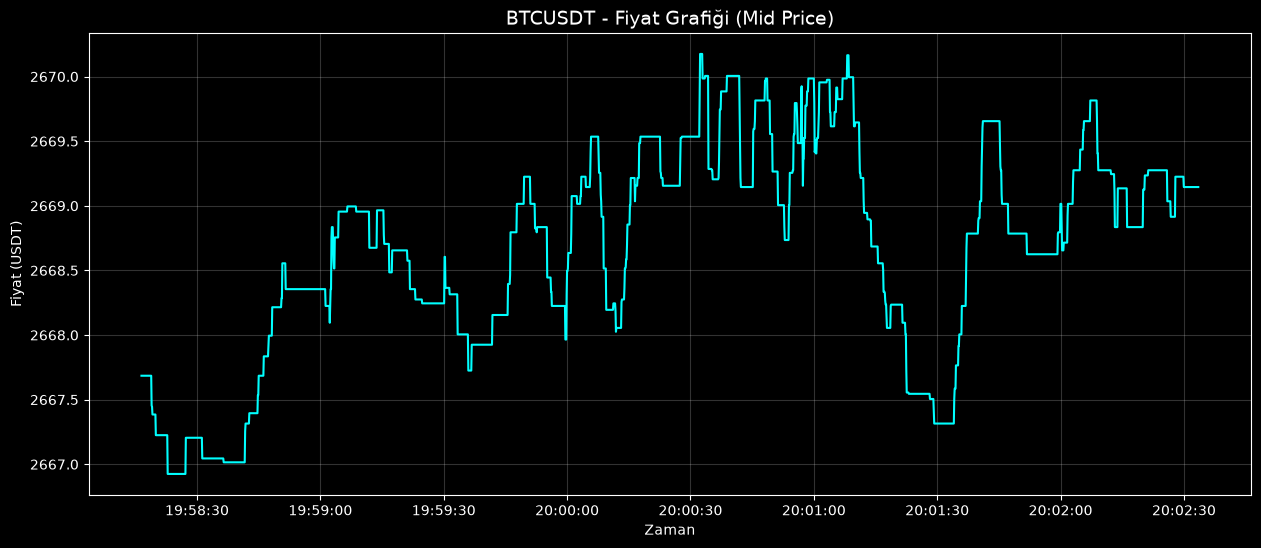

In [6]:
## 2. Mid Price (Orta Fiyat) Çizimi
# Mid Price = (En İyi Alış + En İyi Satış) / 2
df_depth['mid_price'] = (df_depth['bid_price_0'] + df_depth['ask_price_0']) / 2

plt.plot(df_depth['datetime'], df_depth['mid_price'], color='cyan', linewidth=1.5)
plt.title('BTCUSDT - Fiyat Grafiği (Mid Price)', fontsize=14)
plt.xlabel('Zaman')
plt.ylabel('Fiyat (USDT)')
plt.show()

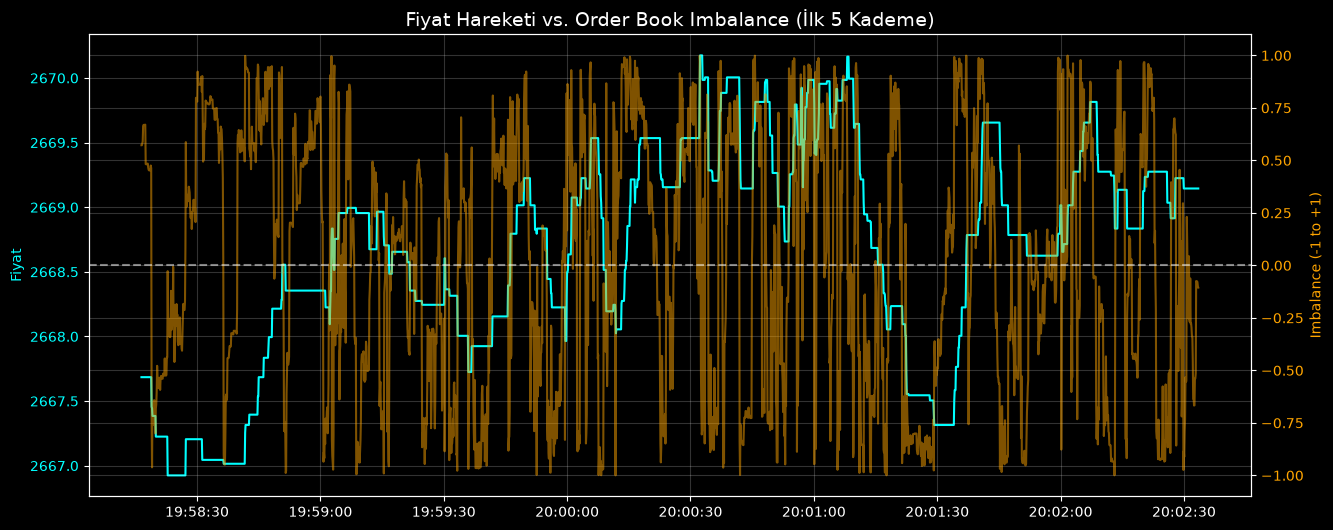

In [7]:
## 3. Order Book Imbalance (OBI) - Emir Defteri Dengesizliği
# OBI, Alış baskısı ile Satış baskısı arasındaki orantısızlığı ölçer. (+1 tam alış, -1 tam satış)
# İlk 5 kademe (Top 5 Levels) baz alınarak hesaplanır.

bid_vols = sum(df_depth[f'bid_qty_{i}'] for i in range(5))
ask_vols = sum(df_depth[f'ask_qty_{i}'] for i in range(5))

df_depth['OBI'] = (bid_vols - ask_vols) / (bid_vols + ask_vols)

fig, ax1 = plt.subplots(figsize=(15, 6))

# Fiyat (Sol eksen)
ax1.plot(df_depth['datetime'], df_depth['mid_price'], color='cyan', label='Fiyat')
ax1.set_ylabel('Fiyat', color='cyan')
ax1.tick_params(axis='y', labelcolor='cyan')

# OBI (Sağ eksen)
ax2 = ax1.twinx()
ax2.plot(df_depth['datetime'], df_depth['OBI'], color='orange', alpha=0.5, label='OBI')
ax2.set_ylabel('Imbalance (-1 to +1)', color='orange')
ax2.axhline(0, color='white', linestyle='--', alpha=0.5)
ax2.tick_params(axis='y', labelcolor='orange')
ax2.set_ylim(-1.1, 1.1)

plt.title('Fiyat Hareketi vs. Order Book Imbalance (İlk 5 Kademe)', fontsize=14)
plt.show()

In [8]:
## 4. Cumulative Volume Delta (CVD) - Kümülatif Hacim Deltası
# Piyasa (Taker) alıcıları ile piyasa (Taker) satıcıları arasındaki net hacim farkı
# is_buyer_maker == True -> İşlemi tetikleyen (Taker) satıcıdır, Maker alıcıdır (- Hacim)
# is_buyer_maker == False -> İşlemi tetikleyen (Taker) alıcıdır, Maker satıcıdır (+ Hacim)

df_trades['trade_side_vol'] = np.where(df_trades['is_buyer_maker'], -df_trades['quantity'], df_trades['quantity'])
df_trades['CVD'] = df_trades['trade_side_vol'].cumsum()

fig, ax1 = plt.subplots(figsize=(15, 6))

# Fiyat (Sol eksen)
ax1.plot(df_trades['datetime'], df_trades['price'], color='cyan', label='Fiyat')
ax1.set_ylabel('Fiyat', color='cyan')
ax1.tick_params(axis='y', labelcolor='cyan')

# CVD (Sağ eksen)
ax2 = ax1.twinx()
ax2.plot(df_trades['datetime'], df_trades['CVD'], color='magenta', linewidth=2, label='CVD')
ax2.set_ylabel('Net Hacim Farkı (BTC)', color='magenta')
ax2.tick_params(axis='y', labelcolor='magenta')

plt.title('Fiyat Hareketi vs. Cumulative Volume Delta (CVD)', fontsize=14)
plt.show()

NameError: name 'df_trades' is not defined

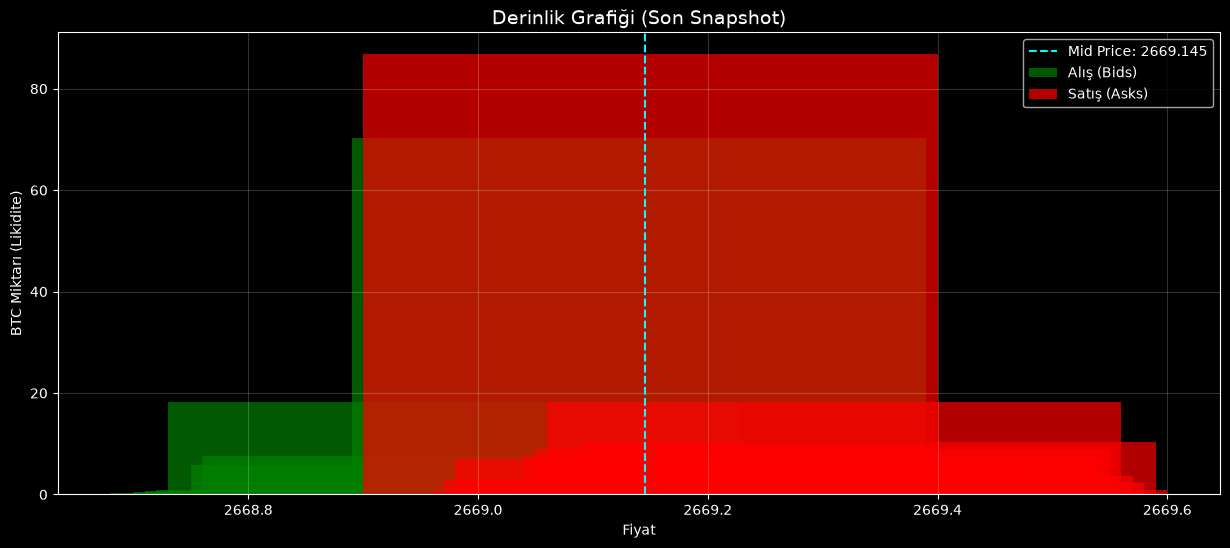

In [9]:
## 5. Sipariş Defteri Derinlik Analizi (Anlık Snapshot)
# Son snapshot üzerinden Alış (Bid) ve Satış (Ask) likiditesini görselleştirme

last_row = df_depth.iloc[-1]

bids_price = [last_row[f'bid_price_{i}'] for i in range(20)]
bids_qty = [last_row[f'bid_qty_{i}'] for i in range(20)]

asks_price = [last_row[f'ask_price_{i}'] for i in range(20)]
asks_qty = [last_row[f'ask_qty_{i}'] for i in range(20)]

plt.figure(figsize=(15, 6))
plt.bar(bids_price, bids_qty, color='green', alpha=0.7, width=0.5, label='Alış (Bids)')
plt.bar(asks_price, asks_qty, color='red', alpha=0.7, width=0.5, label='Satış (Asks)')
plt.axvline(last_row['mid_price'], color='cyan', linestyle='--', label=f"Mid Price: {last_row['mid_price']}")

plt.title('Derinlik Grafiği (Son Snapshot)', fontsize=14)
plt.xlabel('Fiyat')
plt.ylabel('BTC Miktarı (Likidite)')
plt.legend()
plt.show()